# Bernal stacked bilayer graphene: bilayer and bulk graphite

We revisit the skills learnt in the previous section by calculating the electronic band structure for Bernal stacked bilayer graphene and bulk graphite. While doing so, we will introduce a new method to build the system that relies on providing the structural information from external files. This can be particularly useful when reading in relaxed structures from a preliminary LAMMPS calculation for instance.

Up to now, we only had to provide the code with the `Gendata.in` file which contains all the input flags. When using the `ReadXYZ` method, one also has to provide the `generate.xyz` and  `sublatticesSorted.dat` files to inform the code about the position of the atoms and the sublattice to which each of these atom belong. For convenience, we provide these files in the `twistronics2023` folder you downloaded earlier.

## AB-stacked bilayer graphene

In the following figure, we illustrate Bernal stacked bilayer graphene. This is considered to be energetically the most stable configurations when stacking two graphene layers on top of each other. Similarly to the graphene system, this system can be represented using 4 atoms in the unit cell.

Task: 
- [ ] Run the following code cell to obtain the bandstructure. You might need a lot of k-points if you want to capture the fine-features close to the K-point. Because the system is small, it'll still be doable in a reasonable amount of time.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "bilayerGraphene/bandstructure/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem ReadXYZ", # To build graphene using the built-in grabnes methods
                     "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                     "CellSize 1", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "twoLayers .true.", # Specify to the code that this is a 2 layer system
                     "twoLayersZ1 1.675", # Specify approximately the z coordinate of the bottom layer
                     "twoLayersZ2 5.025" # Specify approximately the z coordinate of the top layer
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 50", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 5", # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      "Neigh.LayerDistFactor 1.2", # Not importat
                      "nonBulkSmall .true." # We are not doing a bulk calculation
                      #"BulkSmall .true.",
                      #"Bulk .true."
                      ]

inputStrings_diag = ["Bands.NumPoints 50000",
                     "&begin Bands.Path 4",
                     "0.0   0.0  0.0", # Gamma
                     "0.5   0.0 0.0", # M
                     "2/3   1/3 0.0", # K
                     "0.0   0.0  0.0", # Gamma
                     "&end Bands.Path",
                    ]
                     
                     

      

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC", # Hybrid TC model, use it when intralayer interactions follow F2G2 and interlayer follow reparametrized TC model
                    "forceBilayerF2G2Intralayer .true." # Use the bilayer F2G2 intralayer terms rather than the single layer F2G2 terms
                    ] 


inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/bilayerGraphene/bandstructure//generate.bands.dat' mode='r' encoding='UTF-8'>
4 136604


Text(0, 0.5, 'E (eV)')

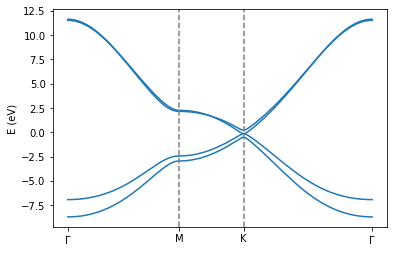

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.2)
plt.axvline(1.474633, linestyle="dashed",color="grey")
plt.axvline(2.326013, linestyle="dashed",color="grey")
plt.xticks([0.0, 1.474633, 2.326013,4.028773],[r"$\Gamma$", "M", "K", r"$\Gamma$"])
#plt.ylim(-0.1446,-0.1438) # Uncomment this to focus on the fine features at the K-point
#plt.xlim(2.32601-0.003,2.32601+0.006) # Uncomment this to focus on the fine features at the K-point
plt.ylabel("E (eV)")

If you correctly ran the calculation, you should see an accurate version of the electronic bandstructure for Bernal stacked graphene. For comparion purposes, see for instance here.

Bonus task: 
- [ ] change the working directory to calculate also the AA stacking electronic bandstructure of bilayer graphene. We provide the `generate.xyz` file in the `bilayerGraphene/bandstructureAA` subfolder.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "bilayerGraphene/bandstructureAA/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem ReadXYZ", # To build graphene using the built-in grabnes methods
                     "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                     "CellSize 1", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "twoLayers .true.", # Specify to the code that this is a 2 layer system
                     "twoLayersZ1 1.675", # Specify approximately the z coordinate of the bottom layer
                     "twoLayersZ2 5.025" # Specify approximately the z coordinate of the top layer
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 50", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 5", # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      "Neigh.LayerDistFactor 1.2", # Not importat
                      "nonBulkSmall .true." # We are not doing a bulk calculation
                      #"BulkSmall .true.",
                      #"Bulk .true."
                      ]

inputStrings_diag = ["Bands.NumPoints 50000",
                     "&begin Bands.Path 4",
                     "0.0   0.0  0.0", # Gamma
                     "0.5   0.0 0.0", # M
                     "2/3   1/3 0.0", # K
                     "0.0   0.0  0.0", # Gamma
                     "&end Bands.Path",
                    ]
                     
                     

      

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC", # Hybrid TC model, use it when intralayer interactions follow F2G2 and interlayer follow reparametrized TC model
                    "forceBilayerF2G2Intralayer .true." # Use the bilayer F2G2 intralayer terms rather than the single layer F2G2 terms
                    ] 


inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/bilayerGraphene/bandstructureAA//generate.bands.dat' mode='r' encoding='UTF-8'>
4 136604


Text(0, 0.5, 'E (eV)')

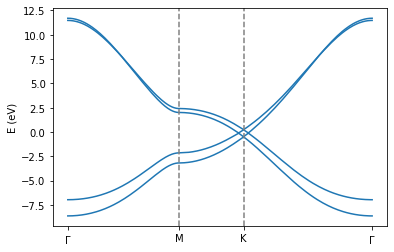

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.2)
plt.axvline(1.474633, linestyle="dashed",color="grey")
plt.axvline(2.326013, linestyle="dashed",color="grey")
plt.xticks([0.0, 1.474633, 2.326013,4.028773],[r"$\Gamma$", "M", "K", r"$\Gamma$"])
#plt.ylim(-0.1446,-0.1438) # Uncomment this to focus on the fine features at the K-point
#plt.xlim(2.32601-0.003,2.32601+0.006) # Uncomment this to focus on the fine features at the K-point
plt.ylabel("E (eV)")

## Graphite

It is straightforward to switch from the previous bilayer calculations by adjusting the structural input file so that interactions between the bottom of the unit cell and the top of the unit cell are taken into account, hence allowing us to calculate the bandstructure for graphite.

Task:
- [ ] Run the following cell. Note the differences between the previous Bernal stacked bilayer calculations and these bulk calculations. 

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "graphite/"
#os.mkdir(workingDir)
workingDir = rootDir + "graphite/bandstructure/"
#os.mkdir(workingDir)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem ReadXYZ", # To build graphene using the built-in grabnes methods
                     "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                     "CellSize 1", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "twoLayers .true.", # Specify to the code that this is a 2 layer system
                     "twoLayersZ1 1.675", # Specify approximately the z coordinate of the bottom layer
                     "twoLayersZ2 5.025" # Specify approximately the z coordinate of the top layer
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 50", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 5", # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      "Neigh.LayerDistFactor 1.2", # Not importat
                      "BulkSmall .true.", # We are doing a smnall cell bulk calculation
                      "Bulk .true."  #We are not doing a bulk calculation
                      ]

inputStrings_diag = ["Bands.NumPoints 10",
                     "&begin Bands.Path 8",
                     "0.0   0.0  0.0", # Gamma
                     "1/3   0.0-1/3 0.0", # K
                     "0.5   0.0 0.0", # K
                     "0.0   0.0  0.0", # Gamma
                     "0.0   0.0  0.5",
                     "1/3   0.0-1/3 0.5",
                     "0.5   0.0 0.5",
                     "0.0   0.0  0.5",
                     "&end Bands.Path",
                    ]
                     

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC", # Hybrid TC model, use it when intralayer interactions follow F2G2 and interlayer follow reparametrized TC model
                    "forceBilayerF2G2Intralayer .true." # Use the bilayer F2G2 intralayer terms rather than the single layer F2G2 terms
                    ] 


inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:

os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/graphite/bandstructure//generate.bands.dat' mode='r' encoding='UTF-8'>
4 52


Text(0, 0.5, 'E (eV)')

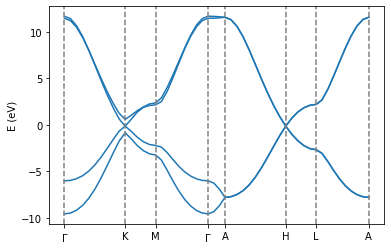

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.2)
#plt.axvline(0.491544*3)
#plt.axvline(0.775337*3
plt.axvline(0.0, linestyle="dashed",color="grey")
plt.axvline(1.702628, linestyle="dashed",color="grey")
plt.axvline(2.553943, linestyle="dashed",color="grey")
plt.axvline(4.028462, linestyle="dashed",color="grey")
plt.axvline(4.497357, linestyle="dashed",color="grey")
plt.axvline(6.199985, linestyle="dashed",color="grey")
plt.axvline(7.051300, linestyle="dashed",color="grey")
plt.axvline(8.525820, linestyle="dashed",color="grey")
plt.xticks([0.0, 1.702628, 2.553943,4.028462,4.497357,6.199985,7.051300,8.525820],[r"$\Gamma$", "K", "M", r"$\Gamma$", "A", "H", "L", "A"])
plt.ylabel("E (eV)")
